# From one Mars photo to 3D ground

Each step below is one idea, run on a real Curiosity Navcam photo (sol 1000, 30 May 2015).
The outputs are already saved under each cell, so you can read it like a book. Re-run it to watch it happen.

**Free GPU (Colab) from VS Code:** open this notebook, click **Select Kernel** (top right) → **Colab** → **New Colab Server** →
pick a **GPU** (T4) → sign in with Google. Then **Run All**. On colab.research.google.com: *Runtime → Change runtime type → T4 GPU*.
It also runs on a laptop CPU; Depth Anything Small just takes a few seconds longer.

## 0 · Setup

In [1]:
import sys, time, re, json, urllib.request
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt, torch
IN_COLAB = 'google.colab' in sys.modules
plt.rcParams.update({'figure.dpi': 90, 'axes.titlesize': 10})
print('Running on', 'Colab' if IN_COLAB else 'this computer', '| GPU:',
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU is fine)')

Running on this computer | GPU: Quadro T2000 with Max-Q Design


## 1 · Get the data
Three products from NASA's archive (PDS Imaging Node), each a text label `.LBL` plus binary data `.IMG`:
`RAS` = the photo, `XYZ` = the 3D point for every pixel, `RNG` = distance from the camera for every pixel.

In [2]:
BASE = 'https://planetarydata.jpl.nasa.gov/img/data/msl/MSLNAV_1XXX/DATA_V1/SOL01000/'
STEM = 'NLB_486270860{}LF0481570NCAM00323M1'
DATA = Path('../sample') if Path('../sample', STEM.format('XYZ') + '.IMG').exists() else Path('data')
DATA.mkdir(exist_ok=True)
for kind in ['RAS', 'XYZ', 'RNG']:
    for ext in ['.LBL', '.IMG']:
        f = DATA / (STEM.format(kind) + ext)
        if not f.exists():
            urllib.request.urlretrieve(BASE + f.name, f)
        print(f'{f.name:44s} {f.stat().st_size / 1e6:6.2f} MB')

NLB_486270860RASLF0481570NCAM00323M1.LBL       0.03 MB
NLB_486270860RASLF0481570NCAM00323M1.IMG       2.14 MB
NLB_486270860XYZLF0481570NCAM00323M1.LBL       0.03 MB
NLB_486270860XYZLF0481570NCAM00323M1.IMG      12.64 MB
NLB_486270860RNGLF0481570NCAM00323M1.LBL       0.03 MB
NLB_486270860RNGLF0481570NCAM00323M1.IMG       4.25 MB


## 2 · A tiny reader for NASA's file format
You don't need to study this cell yet. It reads the label text and the binary grid, and holds the two bits of
maths we use later (the camera model and the rover's position). Later steps explain each piece.

In [3]:
def read_label(path):
    text = re.sub(r"/\*.*?\*/", "", Path(path).read_text(errors="ignore"))
    out, stack, key, buf = [], [], None, ""
    for line in text.splitlines():
        if key is not None:
            buf += " " + line.strip()
            if buf.count("(") <= buf.count(")") and buf.count('"') % 2 == 0:
                out.append((tuple(stack), key, buf.strip())); key = None
            continue
        m = re.match(r"\s*([\^A-Z0-9_:]+)\s*=\s*(.*)$", line)
        if not m: continue
        k, v = m.group(1), m.group(2).strip()
        if k in ("GROUP", "OBJECT"): stack.append(v)
        elif k in ("END_GROUP", "END_OBJECT"): stack.pop()
        elif v.count("(") > v.count(")") or v.count('"') % 2: key, buf = k, v
        else: out.append((tuple(stack), k, v))
    return out

def get(lbl, key, group=None):
    return next(v for p, k, v in lbl if k == key and (group is None or group in p))

def nums(v):
    return tuple(float(x) for x in re.findall(r"-?\d+\.?\d*(?:[eE][-+]?\d+)?", v.split("<")[0]))

def read_product(kind):
    lbl = read_label(DATA / (STEM.format(kind) + ".LBL"))
    rec, start = int(get(lbl, "RECORD_BYTES")), int(nums(get(lbl, "^IMAGE").split(",")[-1])[0])
    L, S, B = (int(get(lbl, k, "IMAGE")) for k in ("LINES", "LINE_SAMPLES", "BANDS"))
    dt = {"MSB_INTEGER": ">i2", "IEEE_REAL": ">f4"}[get(lbl, "SAMPLE_TYPE", "IMAGE")]
    a = np.fromfile(DATA / (STEM.format(kind) + ".IMG"), dtype=dt, count=L * S * B,
                    offset=(start - 1) * rec).astype(np.float32).reshape(B, L, S)
    return (a[0] if B == 1 else a), lbl

class CAHV:
    def __init__(self, lbl):
        g = "GEOMETRIC_CAMERA_MODEL_PARMS"
        self.C, self.A, self.H, self.V = (np.array(nums(get(lbl, f"MODEL_COMPONENT_{i}", g))) for i in range(1, 5))
    def project(self, P):
        d = P - self.C; z = d @ self.A
        return d @ self.H / z, d @ self.V / z, z
    def rays(self, w, h):
        x, y = np.meshgrid(np.arange(w, dtype=float), np.arange(h, dtype=float))
        r = np.cross(self.V - y[..., None] * self.A, self.H - x[..., None] * self.A)
        r /= np.linalg.norm(r, axis=-1, keepdims=True)
        return r * np.sign(r @ self.A)[..., None]

def quat_to_matrix(q):
    s, x, y, z = q
    return np.array([[1-2*(y*y+z*z), 2*(x*y-s*z), 2*(x*z+s*y)],
                     [2*(x*y+s*z), 1-2*(x*x+z*z), 2*(y*z-s*x)],
                     [2*(x*z-s*y), 2*(y*z+s*x), 1-2*(x*x+y*y)]])
print("reader ready")

reader ready


## 3 · Read the label (the `.LBL` file is plain text)
It says when and where the photo was taken, how the camera was pointed, and where the rover stood.

In [4]:
img, lbl_img = read_product('RAS')
xyz, lbl = read_product('XYZ')
rng, lbl_rng = read_product('RNG')
for key in ['PLANET_DAY_NUMBER', 'START_TIME', 'INSTRUMENT_ID', 'ROVER_MOTION_COUNTER']:
    print(f'{key:24s}', get(lbl, key))
print()
print('Camera model (CAHV), in the', get(lbl, 'REFERENCE_COORD_SYSTEM_NAME', 'GEOMETRIC_CAMERA_MODEL_PARMS'))
for i, name in enumerate(['C centre (m)', 'A axis', 'H horizontal', 'V vertical'], 1):
    print(f'  {name:14s}', get(lbl, f'MODEL_COMPONENT_{i}', 'GEOMETRIC_CAMERA_MODEL_PARMS'))
print()
print('Rover position in the SITE frame:', get(lbl, 'ORIGIN_OFFSET_VECTOR', 'ROVER_COORD_SYSTEM_PARMS'), 'metres')
print('Rover rotation (quaternion):    ', get(lbl, 'ORIGIN_ROTATION_QUATERNION', 'ROVER_COORD_SYSTEM_PARMS'))

PLANET_DAY_NUMBER        1000
START_TIME               2015-05-30T15:30:24.436
INSTRUMENT_ID            "NAV_LEFT_B"
ROVER_MOTION_COUNTER     (48,1570,82,272,0,0,448,162,24,0)

Camera model (CAHV), in the "ROVER_NAV_FRAME"
  C centre (m)   (0.682801,0.346785,-1.90745)
  A axis         (0.495682,-0.823973,0.274503)
  H horizontal   (1305.31,216.775,139.893)
  V vertical     (78.4073,-131.889,1320.31)

Rover position in the SITE frame: (-2.58878,-73.3402,-2.44594) metres
Rover rotation (quaternion):     (0.332161,-0.0754662,-0.0622262,0.938137)


## 4 · The photo is a grid of numbers

shape (1024, 1024) | brightness from 0.0 to 4095.0 (12-bit camera)
top-left 4x4 corner of the grid:
[[   0    0    0    0]
 [   0    0    0    0]
 [   0  726  914 1142]
 [   0  416  578  730]]


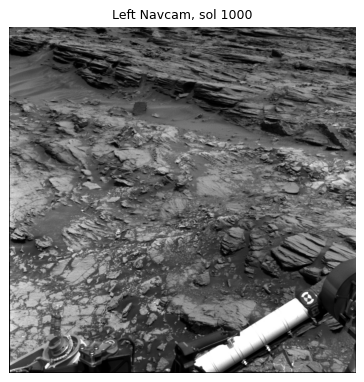

In [5]:
print('shape', img.shape, '| brightness from', img.min(), 'to', img.max(), '(12-bit camera)')
print('top-left 4x4 corner of the grid:'); print(img[:4, :4].astype(int))
lo, hi = np.percentile(img[img > 0], [0.5, 99.5])
img8 = (np.clip((img - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
plt.figure(figsize=(5, 5)); plt.imshow(img8, cmap='gray'); plt.title('Left Navcam, sol 1000'); plt.axis('off'); plt.show()

## 5 · The XYZ file: three numbers per pixel
For each pixel: the X, Y, Z position (metres, **site frame**) of the spot that pixel sees. `(0, 0, 0)` means stereo found no match.

pixel row  700, col  500:  X=  -2.812  Y= -70.007  Z= -2.711 
pixel row  300, col  600:  X=   0.000  Y=   0.000  Z=  0.000   <- hole
pixel row  900, col  950:  X=   0.000  Y=   0.000  Z=  0.000   <- hole

pixels with 3D: 66.1%


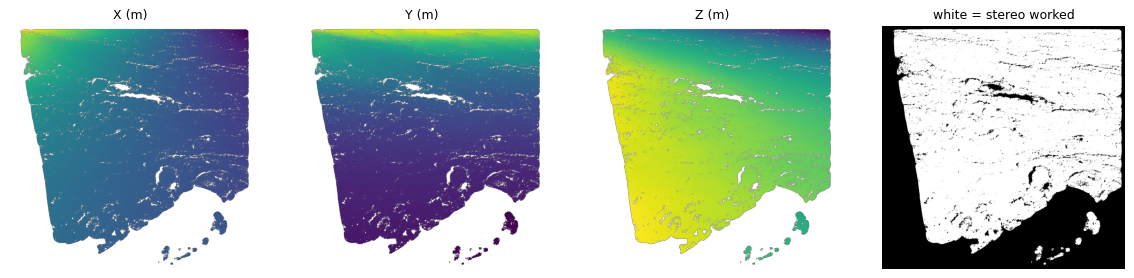

In [6]:
for (row, col) in [(700, 500), (300, 600), (900, 950)]:
    X, Y, Z = xyz[:, row, col]
    print(f'pixel row {row:4d}, col {col:4d}:  X={X:8.3f}  Y={Y:8.3f}  Z={Z:7.3f}', '  <- hole' if X == Y == Z == 0 else '')
valid = np.abs(xyz).sum(0) > 0
print(f'\npixels with 3D: {valid.mean():.1%}')
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i, n in enumerate('XYZ'):
    ax[i].imshow(np.where(valid, xyz[i], np.nan)); ax[i].set_title(f'{n} (m)'); ax[i].axis('off')
ax[3].imshow(valid, cmap='gray'); ax[3].set_title('white = stereo worked'); ax[3].axis('off'); plt.show()

## 6 · The camera model turns a 3D point into a pixel
`column = (P−C)·H / (P−C)·A`, `row = (P−C)·V / (P−C)·A`. The camera model is in the **rover** frame and XYZ is in the
**site** frame, so first move the point into the rover frame with the rover's position and rotation.

In [7]:
cam = CAHV(lbl)
R = quat_to_matrix(nums(get(lbl, 'ORIGIN_ROTATION_QUATERNION', 'ROVER_COORD_SYSTEM_PARMS')))
t = np.array(nums(get(lbl, 'ORIGIN_OFFSET_VECTOR', 'ROVER_COORD_SYSTEM_PARMS')))
row, col = 700, 500
P_site = xyz[:, row, col].astype(float)
P_rover = R.T @ (P_site - t)                       # site -> rover
d = P_rover - cam.C
print('point (site frame)  ', P_site.round(3))
print('point (rover frame) ', P_rover.round(3))
print('P - C               ', d.round(3), '  (from camera to point)')
print(f'(P-C)·A = {d @ cam.A:.3f} m   <- depth: how far in front of the camera')
print(f'column  = {(d @ cam.H) / (d @ cam.A):.2f}  (we started at {col})')
print(f'row     = {(d @ cam.V) / (d @ cam.A):.2f}  (we started at {row})')

P_all = np.moveaxis(xyz, 0, -1).astype(float)
u, v, depth = cam.project((P_all - t) @ R)
ys, xs = np.nonzero(valid)
err = np.hypot(u[ys, xs] - xs, v[ys, xs] - ys)
print(f'\nall {len(err):,} points: median re-projection error {np.median(err):.2f} px')

point (site frame)   [ -2.812 -70.007  -2.711]
point (rover frame)  [ 2.306 -2.39  -0.441]
P - C                [ 1.624 -2.737  1.466]   (from camera to point)
(P-C)·A = 3.462 m   <- depth: how far in front of the camera
column  = 500.00  (we started at 500)
row     = 700.07  (we started at 700)



all 693,248 points: median re-projection error 0.10 px


## 7 · Depth map, and the rover frame vs the site frame
Depth = `(P−C)·A` for every pixel. Check the frame maths: the camera centre moved into the site frame should equal
the range origin NASA wrote in the `RNG` label.

camera centre, site frame (ours): [ -2.977 -73.049  -4.443]
range origin from the RNG label:   (-2.97707, -73.0488, -4.44322)
depth from 1.34 m to 19.58 m; pixel (700,500) is 3.46 m deep and 3.50 m away in a straight line


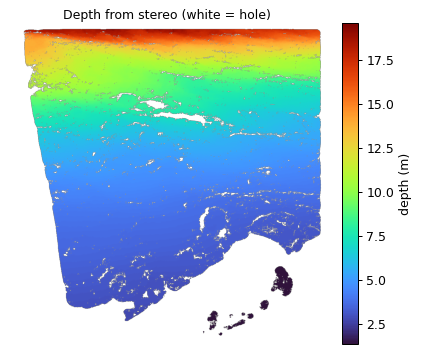

In [8]:
depth = np.where(valid, depth, np.nan)
C_site = R @ cam.C + t
print('camera centre, site frame (ours):', C_site.round(3))
print('range origin from the RNG label:  ', nums(get(lbl_rng, 'MSL:RANGE_ORIGIN_VECTOR')))
print(f'depth from {np.nanmin(depth):.2f} m to {np.nanmax(depth):.2f} m; pixel (700,500) is {depth[700, 500]:.2f} m deep '
      f'and {rng[700, 500]:.2f} m away in a straight line')
plt.figure(figsize=(5, 5)); plt.imshow(depth, cmap='turbo'); plt.colorbar(label='depth (m)', fraction=0.046)
plt.title('Depth from stereo (white = hole)'); plt.axis('off'); plt.show()

## 8 · Depth Anything V2: depth from one photo
A neural network that learned depth clues from millions of photos. Its answer has **no units**: bigger = closer.

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


ran on cuda in 0.7 s; output from 0.04 to 7.82 (no units)
  pixel (950,300): model says 6.63   stereo depth nan m
  pixel (600,500): model says 2.26   stereo depth 3.89 m
  pixel (100,500): model says 0.44   stereo depth 12.37 m


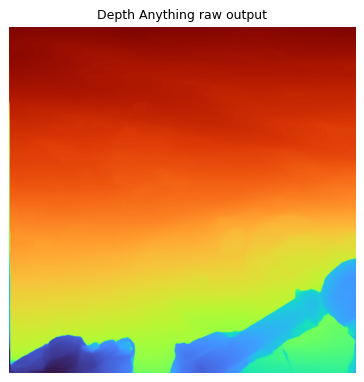

In [9]:
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
MODEL = 'depth-anything/Depth-Anything-V2-Small-hf'   # 25M parameters, Apache-2.0
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
proc = AutoImageProcessor.from_pretrained(MODEL)
model = AutoModelForDepthEstimation.from_pretrained(MODEL).to(dev).eval()
t0 = time.time()
with torch.no_grad():
    out = model(**proc(images=Image.fromarray(np.stack([img8] * 3, -1)), return_tensors='pt').to(dev)).predicted_depth
    rel = torch.nn.functional.interpolate(out[None], size=img.shape, mode='bicubic', align_corners=False)[0, 0].cpu().numpy()
print(f'ran on {dev} in {time.time() - t0:.1f} s; output from {rel.min():.2f} to {rel.max():.2f} (no units)')
for (r, c) in [(950, 300), (600, 500), (100, 500)]:
    print(f'  pixel ({r},{c}): model says {rel[r, c]:.2f}   stereo depth {depth[r, c]:.2f} m')
plt.figure(figsize=(5, 5)); plt.imshow(rel, cmap='turbo_r'); plt.title('Depth Anything raw output'); plt.axis('off'); plt.show()

## 9 · Give it units: fit two numbers
Find `s` and `t` so that `s × output + t ≈ 1 / stereo depth`, using only some stereo pixels. Then grade on pixels it never saw.

fitted on 200 stereo pixels: s = 0.09538, t = 0.04177
  pixel (950,300): Depth Anything  1.48 m   stereo   nan m
  pixel (600,500): Depth Anything  3.89 m   stereo  3.89 m
  pixel (100,500): Depth Anything 11.90 m   stereo 12.37 m

 0-4  m: average error  6.3%   within 25%:  99.2%   (204,194 pixels)
 4-8  m: average error  5.1%   within 25%: 100.0%   (284,699 pixels)
 8-12 m: average error  3.8%   within 25%: 100.0%   (123,446 pixels)
12-20 m: average error  4.1%   within 25%: 100.0%   (80,709 pixels)
 0-99 m: average error  5.1%   within 25%:  99.8%   (693,048 pixels)


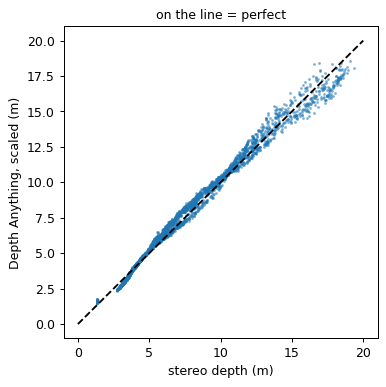

In [10]:
rs = np.random.default_rng(0)
order = rs.permutation(len(ys))
anchors = np.zeros_like(valid); anchors[ys[order[:200]], xs[order[:200]]] = True
test = valid & ~anchors
A = np.stack([rel[anchors], np.ones(anchors.sum())], 1)
s, b = np.linalg.lstsq(A, 1 / depth[anchors], rcond=None)[0]
da = 1 / np.maximum(s * rel + b, 1e-3)
print(f'fitted on 200 stereo pixels: s = {s:.5f}, t = {b:.5f}')
for (r, c) in [(950, 300), (600, 500), (100, 500)]:
    print(f'  pixel ({r},{c}): Depth Anything {da[r, c]:5.2f} m   stereo {depth[r, c]:5.2f} m')
print()
for lo_, hi_ in [(0, 4), (4, 8), (8, 12), (12, 20), (0, 99)]:
    m = test & (depth >= lo_) & (depth < hi_)
    e = np.abs(da[m] - depth[m]) / depth[m]
    print(f'{lo_:2d}-{hi_:<2d} m: average error {e.mean():5.1%}   within 25%: {np.mean(e < 0.25):6.1%}   ({m.sum():,} pixels)')
pick = rs.choice(np.flatnonzero(test.ravel()), 4000, replace=False)
plt.figure(figsize=(4.5, 4.5)); plt.scatter(depth.ravel()[pick], da.ravel()[pick], s=2, alpha=.4); plt.plot([0, 20], [0, 20], 'k--')
plt.xlabel('stereo depth (m)'); plt.ylabel('Depth Anything, scaled (m)'); plt.title('on the line = perfect'); plt.show()

## 10 · Fill the holes

stereo covers 66% of the photo; with Depth Anything: 97%


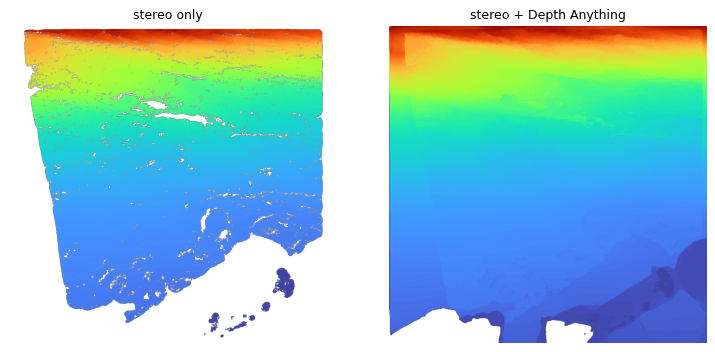

In [11]:
filled = np.where(valid, depth, np.where((da > 1.5) & (da < 25), da, np.nan))
print(f'stereo covers {valid.mean():.0%} of the photo; with Depth Anything: {np.isfinite(filled).mean():.0%}')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, d_, ttl in [(ax[0], depth, 'stereo only'), (ax[1], filled, 'stereo + Depth Anything')]:
    a.imshow(d_, cmap='turbo', vmin=0, vmax=20); a.set_title(ttl); a.axis('off')
plt.show()

## 11 · Back to 3D, and spin it
Each pixel's ray, walked out to its depth, gives a 3D point. Doing this with the stereo depth should rebuild NASA's XYZ file exactly.
Drag the plot below to rotate it.

In [12]:
rays = cam.rays(*img.shape[::-1])
def to_site(dep):
    return (cam.C + rays * (np.nan_to_num(dep) / (rays @ cam.A))[..., None]) @ R.T + t
P_back = to_site(depth)
diff = np.linalg.norm(P_back[valid] - P_all[valid], axis=1)
print(f'rebuilt vs NASA XYZ: median difference {np.median(diff) * 1000:.2f} mm')

import plotly.graph_objects as go, plotly.io as pio
pio.renderers.default = 'colab' if IN_COLAB else 'plotly_mimetype+notebook_connected'
P = to_site(filled); have = np.isfinite(filled) & (filled > 1.5)
sel = rs.choice(np.flatnonzero(have.ravel()), 30000, replace=False)
pts, from_da = P.reshape(-1, 3)[sel], (~valid).ravel()[sel]
east, north, up = pts[:, 1] - t[1], pts[:, 0] - t[0], -(pts[:, 2] - t[2])
fig = go.Figure()
for mask, name, color in [(~from_da, 'stereo (measured)', up[~from_da]), (from_da, 'Depth Anything (estimated)', '#e3a254')]:
    fig.add_trace(go.Scatter3d(x=east[mask], y=north[mask], z=up[mask], mode='markers', name=name,
                               marker=dict(size=1.6, color=color, colorscale='earth' if name.startswith('stereo') else None)))
fig.update_layout(height=520, margin=dict(l=0, r=0, t=30, b=0), title='Drag to rotate (metres from the rover)',
                  scene=dict(aspectmode='data', xaxis_title='east', yaxis_title='north', zaxis_title='up'))
fig.show()

rebuilt vs NASA XYZ: median difference 0.45 mm


## 12 · What an astronaut needs: height and slope from above
Drop the points onto a 0.25 m grid seen from above, then measure the slope. Over 25° is a bad idea on foot.

mapped 172 m²: 72% under 15°, 20% 15-25°, 8% over 25°


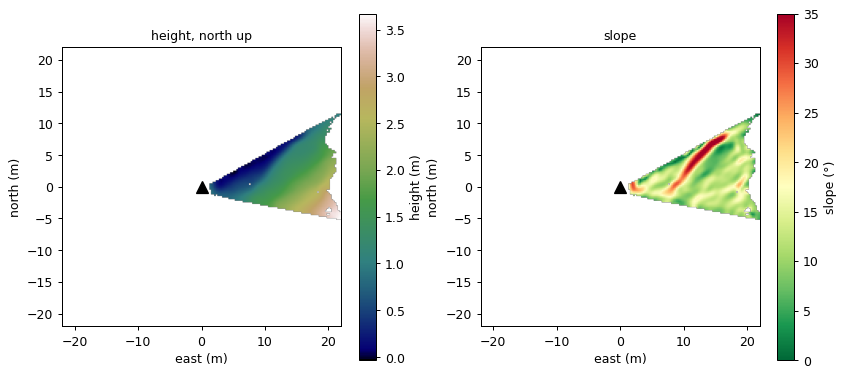

In [13]:
from scipy import ndimage
cell, half = 0.25, 22
P2 =to_site(filled)[have]; e2, n2, u2 = P2[:, 1] - t[1], P2[:, 0] - t[0], -(P2[:, 2] - t[2])
ix, iy = np.floor((e2 + half) / cell).astype(int), np.floor((half - n2) / cell).astype(int)
n = int(2 * half / cell); ok = (ix >= 0) & (ix < n) & (iy >= 0) & (iy < n)
cnt = np.bincount(iy[ok] * n + ix[ok], minlength=n * n).reshape(n, n)
hgt = np.bincount(iy[ok] * n + ix[ok], weights=u2[ok], minlength=n * n).reshape(n, n) / np.maximum(cnt, 1)
w = ndimage.gaussian_filter((cnt > 0).astype(float), 1.5)
hs = ndimage.gaussian_filter(hgt * (cnt > 0), 1.5) / np.maximum(w, 1e-6)
gy, gx = np.gradient(hs, cell)
slope = np.where((cnt > 0) & (w > .3), np.degrees(np.arctan(np.hypot(gx, gy))), np.nan)
sv = slope[np.isfinite(slope)]
print(f'mapped {np.isfinite(slope).sum() * cell * cell:.0f} m²: {np.mean(sv < 15):.0%} under 15°, '
      f'{np.mean((sv >= 15) & (sv < 25)):.0%} 15-25°, {np.mean(sv >= 25):.0%} over 25°')
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ext = [-half, half, -half, half]
im = ax[0].imshow(np.where(cnt > 0, hs, np.nan), cmap='gist_earth', extent=ext); plt.colorbar(im, ax=ax[0], label='height (m)')
im = ax[1].imshow(slope, cmap='RdYlGn_r', vmin=0, vmax=35, extent=ext); plt.colorbar(im, ax=ax[1], label='slope (°)')
for a, ttl in zip(ax, ['height, north up', 'slope']):
    a.plot(0, 0, 'k^', ms=9); a.set_title(ttl); a.set_xlabel('east (m)'); a.set_ylabel('north (m)')
plt.show()

## What you just saw
1. NASA's XYZ file + the camera model + the rover pose agree to a tenth of a pixel and to the millimetre.
2. Depth Anything with **no training**, scaled with 200 stereo pixels, lands within about 5% of stereo and fills every hole.
3. Its weak spot is far away (over about 12 m), where it reads too near. That is where fine-tuning could help:
   notebook `02_finetune_or_not.ipynb` tests exactly that.
4. Merged ground gives a slope map, the layer a Marswalk planner needs.